<a href="https://colab.research.google.com/github/DikshyaL/Nepali-Tokenization-Tax/blob/main/experiment1_data_share.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 1: Does data share *cause* the Nepali tokenization tax?

**The question.** In the main notebook, Nepali costs 11–19% more than Hindi in strong tokenizers even though both use Devanagari. That is an *observation*. This notebook runs a controlled experiment: we train our own tokenizers and change **only** how much Nepali text they see.

**The design.**

- Every tokenizer is trained on the **same total amount of text** (`TOTAL_CHARS`) with the **same vocabulary size**.
- **Hindi's share is fixed** (20%). Only Nepali's share changes: 0%, 1%, 2%, 5%, 10%, 20%, 30%. English fills the rest.
- Each setting is trained **3 times** with different random samples of Wikipedia articles, so we get error bars.
- We then measure parity on the same FLORES-200 sentences as the main notebook. **Marathi** is never in the training data: it is a Devanagari control language.

**What each outcome would mean.**

- Nepali parity falls as its share rises, Hindi stays roughly flat → **data share causes the tax**.
- At 20% Nepali (equal to Hindi), the Nepali/Hindi ratio tells us what is left once data is equal. Close to 1.00 → data explains the gap. Clearly above 1.00 → something about Nepali itself (for example, postpositions written attached to words: *नेपालमा* vs Hindi *नेपाल में*) also adds cost.

**How to run.** First set `QUICK_TEST = True` and Run all (about 5 minutes) to check everything works. Then set it to `False` and Run all again (roughly 20–40 minutes on a standard Colab CPU). Results are saved after every run, so if Colab disconnects, just Run all again and it continues where it stopped.

## 0. Install

In [1]:
!pip install -q -U datasets tokenizers

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


## 1. Settings

In [2]:
import os, re, time, json, random, tarfile, urllib.request, unicodedata, shutil, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from html import escape
from tokenizers import Tokenizer, Regex, models, trainers, pre_tokenizers, decoders, normalizers
warnings.filterwarnings("ignore")

QUICK_TEST = False       # True = small, fast run to test the pipeline

TOTAL_CHARS   = 20_000_000  # characters of training text per tokenizer (same for every run)
VOCAB_SIZE    = 32_000
HINDI_SHARE   = 0.20        # fixed in every run
NEPALI_SHARES = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30]
SEEDS         = [0, 1, 2]
WIKI_DUMP     = "20231101"  # Wikipedia snapshot on Hugging Face (wikimedia/wikipedia)
POOL_FACTOR   = 1.3         # collect 30% extra text so different seeds draw different articles
RUN_ABLATION  = True        # extra mini-experiment on pre-tokenization (section 9)

if QUICK_TEST:
    TOTAL_CHARS, NEPALI_SHARES, SEEDS = 2_000_000, [0.0, 0.05, 0.20], [0]

EVAL_LANGS = {"eng_Latn": "English", "hin_Deva": "Hindi",
              "npi_Deva": "Nepali", "mar_Deva": "Marathi"}   # Marathi = unseen control
BASELINE = "eng_Latn"

# Pre-tokenization rule: split text into words before BPE learns merges.
# "keep_marks" keeps Devanagari vowel signs (Unicode category M) inside words.
# "gpt2_style" is the older rule that splits words at every vowel sign.
PATTERNS = {
    "keep_marks": r" ?[\p{L}\p{M}]+| ?\p{N}+| ?[^\s\p{L}\p{M}\p{N}]+|\s+(?!\S)|\s+",
    "gpt2_style": r" ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+",
}
MAIN_PATTERN = "keep_marks"

OUT = "exp1_outputs"
os.makedirs(f"{OUT}/images", exist_ok=True)
os.makedirs(f"{OUT}/tokenizers", exist_ok=True)
RESULTS_CSV = f"{OUT}/exp1_results.csv"
print("Run sizes:", f"{TOTAL_CHARS:,} chars,", f"vocab {VOCAB_SIZE:,},",
      f"{len(NEPALI_SHARES)} shares x {len(SEEDS)} seeds = {len(NEPALI_SHARES)*len(SEEDS)} tokenizers")

Run sizes: 20,000,000 chars, vocab 32,000, 7 shares x 3 seeds = 21 tokenizers


## 2. Load FLORES-200 (evaluation text)

Same sentences as the main notebook: `dev` + `devtest`, 2,009 per language.

In [3]:
URL, ROOT = "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz", "flores200_dataset"

def load_flores():
    if not os.path.exists(ROOT):
        urllib.request.urlretrieve(URL, "flores200.tar.gz")
        with tarfile.open("flores200.tar.gz") as t:
            try: t.extractall(".", filter="data")
            except TypeError: t.extractall(".")
    out = {}
    for code in EVAL_LANGS:
        sents = []
        for split in ["dev", "devtest"]:
            with open(f"{ROOT}/{split}/{code}.{split}", encoding="utf-8") as f:
                sents += [unicodedata.normalize("NFC", l.rstrip("\n")) for l in f]
        out[code] = sents
    return out

flores = load_flores()
print({EVAL_LANGS[c]: len(s) for c, s in flores.items()})

{'English': 2009, 'Hindi': 2009, 'Nepali': 2009, 'Marathi': 2009}


## 3. Collect Wikipedia text (training text)

We stream articles in random order and keep collecting until we have enough for the largest share we need. Very short stub articles (under 200 characters) are skipped. Text is Unicode-normalized (NFC) so that the same letter is always stored the same way.

In [4]:
from datasets import load_dataset

def clean(t):
    t = unicodedata.normalize("NFC", t)
    t = re.sub(r"\n{2,}", "\n", t).strip()
    return t

def build_pool(lang, max_chars, seed=1234):
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_DUMP}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=seed, buffer_size=5_000)
    pool, total, start = [], 0, time.time()
    for ex in ds:
        t = clean(ex["text"])
        if len(t) < 200:
            continue
        pool.append(t); total += len(t)
        if total >= max_chars:
            break
    print(f"{lang}: {len(pool):,} articles, {total:,} chars ({time.time()-start:.0f}s)")
    return pool, total

need = {
    "en": (1 - HINDI_SHARE - min(NEPALI_SHARES)) * TOTAL_CHARS,
    "hi": HINDI_SHARE * TOTAL_CHARS,
    "ne": max(NEPALI_SHARES) * TOTAL_CHARS,
}
pools = {}
for lang, n_need in need.items():
    pools[lang], got = build_pool(lang, int(n_need * POOL_FACTOR))
    if got < n_need:
        raise ValueError(f"Not enough {lang} text: have {got:,}, need {int(n_need):,}. "
                         f"Lower TOTAL_CHARS or the largest Nepali share.")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

en: 3,834 articles, 20,808,497 chars (16s)
hi: 1,395 articles, 5,203,979 chars (8s)
ne: 4,006 articles, 7,804,246 chars (7s)


### Contamination check

FLORES sentences come from Wikinews, Wikivoyage and Wikibooks, not Wikipedia, so overlap should be close to zero. We check anyway, because a paper reviewer will ask.

In [5]:
lang_to_code = {"en": "eng_Latn", "hi": "hin_Deva", "ne": "npi_Deva"}
for lang, code in lang_to_code.items():
    big = "\n".join(pools[lang])
    hits = sum(1 for s in flores[code] if len(s) > 40 and s in big)
    print(f"{EVAL_LANGS[code]:8s}: {hits} of {len(flores[code])} FLORES sentences found verbatim in the training pool")
    del big

English : 0 of 2009 FLORES sentences found verbatim in the training pool
Hindi   : 0 of 2009 FLORES sentences found verbatim in the training pool
Nepali  : 0 of 2009 FLORES sentences found verbatim in the training pool


## 4. Training and measuring functions

In [6]:
def sample(pool, n_chars, rng):
    out, total = [], 0
    for i in rng.permutation(len(pool)):
        if total >= n_chars:
            break
        t = pool[i][: n_chars - total]
        out.append(t); total += len(t)
    return out

def make_corpus(nepali_share, seed):
    rng = np.random.default_rng(seed)
    english_share = 1 - HINDI_SHARE - nepali_share
    docs = (sample(pools["en"], int(english_share * TOTAL_CHARS), rng)
            + sample(pools["hi"], int(HINDI_SHARE * TOTAL_CHARS), rng)
            + sample(pools["ne"], int(nepali_share * TOTAL_CHARS), rng))
    random.Random(seed).shuffle(docs)
    return docs

def train_bpe(docs, pattern_name=MAIN_PATTERN, vocab_size=VOCAB_SIZE):
    """Byte-level BPE, the same family as GPT-4o and Llama 3 tokenizers."""
    tok = Tokenizer(models.BPE())
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Sequence([
        pre_tokenizers.Split(Regex(PATTERNS[pattern_name]), behavior="isolated"),
        pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=False),
    ])
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=2, show_progress=False,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tok.train_from_iterator(docs, trainer=trainer, length=len(docs))
    return tok

DEVA = re.compile(r"[\u0900-\u097F]")

def evaluate(tok):
    counts = {EVAL_LANGS[c]: sum(len(e.ids) for e in tok.encode_batch(s)) for c, s in flores.items()}
    chars = {EVAL_LANGS[c]: sum(len(x) for x in s) for c, s in flores.items()}
    vocab_text = tok.decode_batch([[i] for i in range(tok.get_vocab_size())])
    row = {f"{l}_tokens": n for l, n in counts.items()}
    row.update({f"{l}_parity": counts[l] / counts["English"] for l in counts})
    row.update({f"{l}_chars_per_token": chars[l] / counts[l] for l in counts})
    row["nepali_hindi_ratio"] = counts["Nepali"] / counts["Hindi"]
    row["devanagari_vocab"] = sum(bool(DEVA.search(s)) for s in vocab_text)
    return row

## 5. Run the experiment

Each line printed is one trained tokenizer. Finished runs are stored in the CSV and skipped if you run this cell again.

In [7]:
done = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()

def already_done(share, seed, pattern):
    if done.empty:
        return False
    m = (np.isclose(done["nepali_share"], share)) & (done["seed"] == seed) & \
        (done["pattern"] == pattern) & (done["total_chars"] == TOTAL_CHARS) & (done["vocab_size"] == VOCAB_SIZE)
    return bool(m.any())

def run(share, seed, pattern=MAIN_PATTERN):
    global done
    if already_done(share, seed, pattern):
        return
    start = time.time()
    tok = train_bpe(make_corpus(share, seed), pattern)
    row = {"nepali_share": share, "seed": seed, "pattern": pattern,
           "total_chars": TOTAL_CHARS, "vocab_size": VOCAB_SIZE, **evaluate(tok),
           "train_seconds": round(time.time() - start)}
    if seed == SEEDS[0]:
        tok.save(f"{OUT}/tokenizers/bpe_{pattern}_ne{int(share*100):02d}.json")
    done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
    done.to_csv(RESULTS_CSV, index=False)
    print(f"Nepali {share:>4.0%} seed {seed} [{pattern}]: Nepali parity {row['Nepali_parity']:.2f}, "
          f"Hindi {row['Hindi_parity']:.2f}, Nepali/Hindi {row['nepali_hindi_ratio']:.2f}  "
          f"({row['train_seconds']}s)")

for share in NEPALI_SHARES:
    for seed in SEEDS:
        run(share, seed)
print("All runs finished.")

Nepali   0% seed 0 [keep_marks]: Nepali parity 1.71, Hindi 1.28, Nepali/Hindi 1.33  (11s)
Nepali   0% seed 1 [keep_marks]: Nepali parity 1.71, Hindi 1.28, Nepali/Hindi 1.34  (13s)
Nepali   0% seed 2 [keep_marks]: Nepali parity 1.70, Hindi 1.28, Nepali/Hindi 1.33  (11s)
Nepali   1% seed 0 [keep_marks]: Nepali parity 1.38, Hindi 1.28, Nepali/Hindi 1.08  (12s)
Nepali   1% seed 1 [keep_marks]: Nepali parity 1.38, Hindi 1.28, Nepali/Hindi 1.08  (12s)
Nepali   1% seed 2 [keep_marks]: Nepali parity 1.37, Hindi 1.27, Nepali/Hindi 1.08  (12s)
Nepali   2% seed 0 [keep_marks]: Nepali parity 1.31, Hindi 1.27, Nepali/Hindi 1.03  (12s)
Nepali   2% seed 1 [keep_marks]: Nepali parity 1.32, Hindi 1.27, Nepali/Hindi 1.04  (12s)
Nepali   2% seed 2 [keep_marks]: Nepali parity 1.31, Hindi 1.27, Nepali/Hindi 1.03  (12s)
Nepali   5% seed 0 [keep_marks]: Nepali parity 1.23, Hindi 1.26, Nepali/Hindi 0.97  (13s)
Nepali   5% seed 1 [keep_marks]: Nepali parity 1.24, Hindi 1.26, Nepali/Hindi 0.98  (13s)
Nepali   5

## 6. Results table (mean ± standard deviation over seeds)

In [8]:
cfg = (done["pattern"] == MAIN_PATTERN) & (done["total_chars"] == TOTAL_CHARS) & (done["vocab_size"] == VOCAB_SIZE)
res = done[cfg]
cols = ["Nepali_parity", "Hindi_parity", "Marathi_parity", "nepali_hindi_ratio", "devanagari_vocab"]
agg = res.groupby("nepali_share")[cols].agg(["mean", "std"])
table = pd.DataFrame(index=agg.index)
for c in cols:
    fmt = "{:.0f} ± {:.0f}" if c == "devanagari_vocab" else "{:.3f} ± {:.3f}"
    table[c] = [fmt.format(m, 0 if np.isnan(s) else s) for m, s in agg[c].values]
table.index = [f"{s:.0%}" for s in table.index]
table.index.name = "Nepali share"
table.to_csv(f"{OUT}/exp1_summary.csv")
table

,Nepali_parity,Hindi_parity,Marathi_parity,nepali_hindi_ratio,devanagari_vocab
Nepali share,,,,,
0%,1.708 ± 0.005,1.279 ± 0.003,1.818 ± 0.015,1.336 ± 0.002,8254 ± 13
1%,1.378 ± 0.008,1.275 ± 0.004,1.802 ± 0.015,1.080 ± 0.003,8628 ± 21
2%,1.314 ± 0.006,1.271 ± 0.003,1.786 ± 0.013,1.034 ± 0.003,8973 ± 11
5%,1.229 ± 0.006,1.261 ± 0.002,1.759 ± 0.011,0.974 ± 0.004,9880 ± 14
10%,1.148 ± 0.002,1.247 ± 0.002,1.732 ± 0.006,0.921 ± 0.002,11245 ± 34
20%,1.073 ± 0.002,1.221 ± 0.003,1.682 ± 0.007,0.879 ± 0.001,13514 ± 32
30%,1.025 ± 0.003,1.196 ± 0.004,1.632 ± 0.009,0.857 ± 0.001,15600 ± 25


## 7. Charts

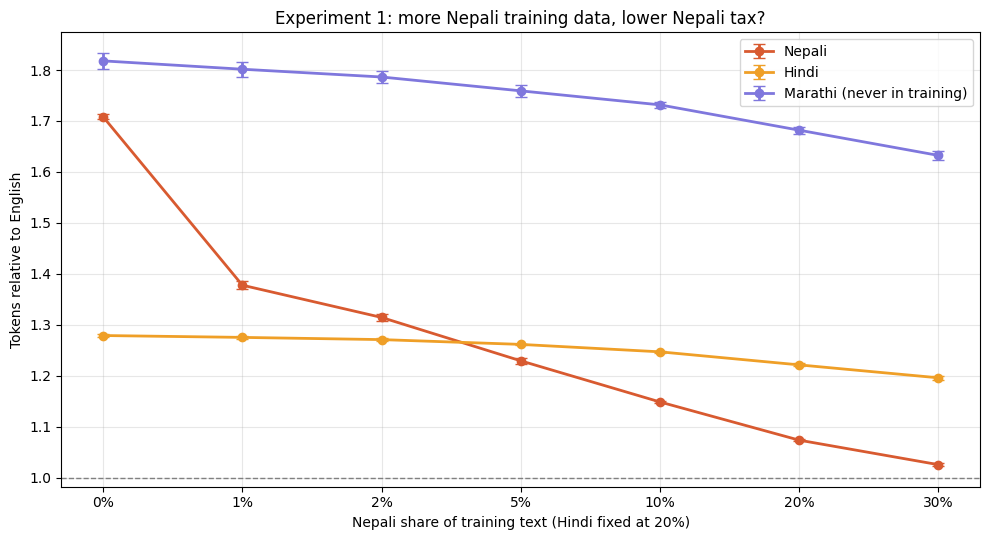

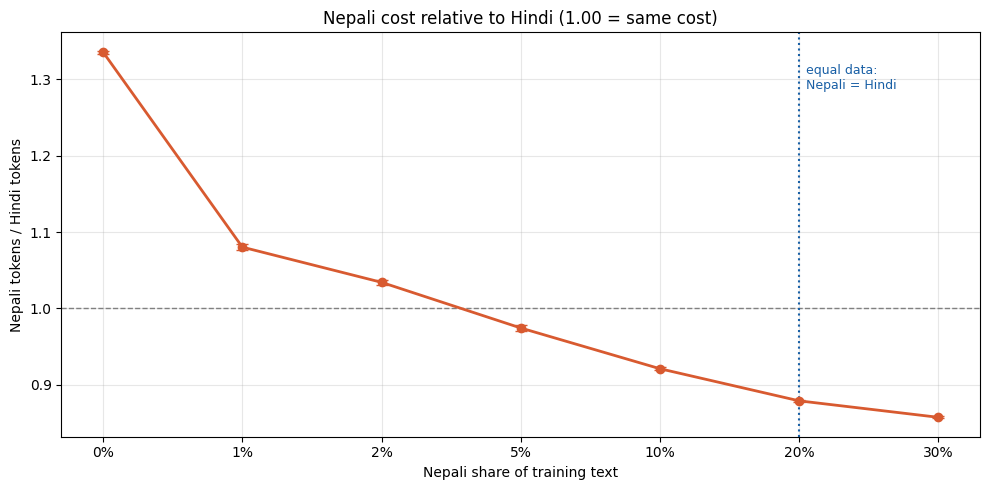

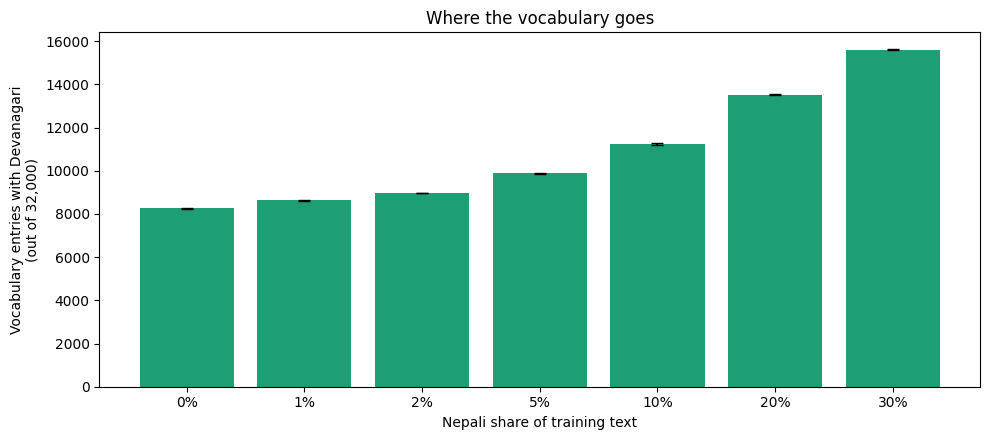

In [9]:
shares = agg.index.values
x = np.arange(len(shares))
labels = [f"{s:.0%}" for s in shares]

# Chart 1: parity vs Nepali share
fig, ax = plt.subplots(figsize=(10, 5.5))
for lang, color in [("Nepali", "#D85A30"), ("Hindi", "#EF9F27"), ("Marathi", "#7F77DD")]:
    m, s = agg[f"{lang}_parity"]["mean"], agg[f"{lang}_parity"]["std"].fillna(0)
    ax.errorbar(x, m, yerr=s, marker="o", capsize=4, lw=2, color=color,
                label=lang + (" (never in training)" if lang == "Marathi" else ""))
ax.axhline(1.0, color="gray", ls="--", lw=1)
ax.set_xticks(x, labels)
ax.set_xlabel(f"Nepali share of training text (Hindi fixed at {HINDI_SHARE:.0%})")
ax.set_ylabel("Tokens relative to English")
ax.set_title("Experiment 1: more Nepali training data, lower Nepali tax?")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/images/exp1_parity_vs_share.png", dpi=150, bbox_inches="tight"); plt.show()

# Chart 2: Nepali / Hindi ratio
fig, ax = plt.subplots(figsize=(10, 5))
m, s = agg["nepali_hindi_ratio"]["mean"], agg["nepali_hindi_ratio"]["std"].fillna(0)
ax.errorbar(x, m, yerr=s, marker="o", capsize=4, lw=2, color="#D85A30")
ax.axhline(1.0, color="gray", ls="--", lw=1)
if HINDI_SHARE in list(shares):
    ax.axvline(list(shares).index(HINDI_SHARE), color="#185FA5", ls=":", lw=1.5)
    ax.text(list(shares).index(HINDI_SHARE) + 0.05, ax.get_ylim()[1] * 0.97,
            "equal data:\nNepali = Hindi", color="#185FA5", va="top", fontsize=9)
ax.set_xticks(x, labels)
ax.set_xlabel("Nepali share of training text")
ax.set_ylabel("Nepali tokens / Hindi tokens")
ax.set_title("Nepali cost relative to Hindi (1.00 = same cost)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/images/exp1_nepali_hindi_ratio.png", dpi=150, bbox_inches="tight"); plt.show()

# Chart 3: how many vocabulary slots go to Devanagari
fig, ax = plt.subplots(figsize=(10, 4.5))
m, s = agg["devanagari_vocab"]["mean"], agg["devanagari_vocab"]["std"].fillna(0)
ax.bar(x, m, yerr=s, capsize=4, color="#1D9E75")
ax.set_xticks(x, labels)
ax.set_xlabel("Nepali share of training text")
ax.set_ylabel(f"Vocabulary entries with Devanagari\n(out of {VOCAB_SIZE:,})")
ax.set_title("Where the vocabulary goes")
plt.tight_layout(); plt.savefig(f"{OUT}/images/exp1_devanagari_vocab.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. See the difference: one Nepali sentence, three tokenizers

The same sentence split by tokenizers trained with little, some, and a lot of Nepali.

In [10]:
IDX = 0
COLORS = ["#FAC775", "#9FE1CB", "#CECBF6", "#F5C4B3"]
sentence = flores["npi_Deva"][IDX]
out = f"<p><b>Sentence:</b> {escape(sentence)}</p>"
for share in [NEPALI_SHARES[0], NEPALI_SHARES[len(NEPALI_SHARES)//2], NEPALI_SHARES[-1]]:
    path = f"{OUT}/tokenizers/bpe_{MAIN_PATTERN}_ne{int(share*100):02d}.json"
    if not os.path.exists(path):
        continue
    tok = Tokenizer.from_file(path)
    ids = tok.encode(sentence).ids
    chips = "".join(f'<span style="background:{COLORS[i%4]};color:#222;padding:2px 5px;margin:2px;'
                    f'border-radius:4px;display:inline-block">{escape(tok.decode([t]).replace(" ", "␣"))}</span>'
                    for i, t in enumerate(ids))
    out += f"<p><b>Trained with {share:.0%} Nepali</b> ({len(ids)} tokens)<br>{chips}</p>"
display(HTML(out))

## 9. Mini-experiment: script handling vs data

Before BPE learns anything, text is split into "words" by a rule (a regular expression). Older rules, like GPT-2's and GPT-4's `cl100k`, treat Devanagari vowel signs (ा ि ी े etc.) as non-letters and cut words apart at every one of them. If that is happening, **no amount of Nepali data can produce whole-word tokens**.

Here we train with both rules at two Nepali shares (seed 0 only). If the `gpt2_style` tokenizers barely improve with more Nepali, while `keep_marks` ones do, that is evidence that in weak tokenizers the bottleneck is the splitting rule, not the data.

In [11]:
print("How each rule splits a Nepali phrase before BPE:")
for name in PATTERNS:
    pt = pre_tokenizers.Split(Regex(PATTERNS[name]), behavior="isolated")
    print(f"  {name:11s}", [p for p, _ in pt.pre_tokenize_str("नेपालमा बस्ने मानिसहरू")])

if RUN_ABLATION:
    ablation_shares = [0.05, 0.20] if not QUICK_TEST else [0.05]
    for share in ablation_shares:
        for pattern in PATTERNS:
            run(share, SEEDS[0], pattern)
    ab = done[(done["seed"] == SEEDS[0]) & done["nepali_share"].isin(ablation_shares)
              & (done["total_chars"] == TOTAL_CHARS) & (done["vocab_size"] == VOCAB_SIZE)]
    ab_table = ab.pivot_table(index="pattern", columns="nepali_share",
                              values=["Nepali_parity", "Hindi_parity", "nepali_hindi_ratio"]).round(3)
    ab_table.to_csv(f"{OUT}/exp1_ablation.csv")
    display(ab_table)

How each rule splits a Nepali phrase before BPE:
  keep_marks  ['नेपालमा', ' बस्ने', ' मानिसहरू']
  gpt2_style  ['न', 'े', 'प', 'ा', 'लम', 'ा', ' बस', '्', 'न', 'े', ' म', 'ा', 'न', 'ि', 'सहर', 'ू']
Nepali   5% seed 0 [gpt2_style]: Nepali parity 3.13, Hindi 3.00, Nepali/Hindi 1.04  (13s)
Nepali  20% seed 0 [gpt2_style]: Nepali parity 3.09, Hindi 2.98, Nepali/Hindi 1.04  (15s)


Hindi_parity        Nepali_parity        nepali_hindi_ratio  \
nepali_share         0.05   0.20          0.05   0.20               0.05   
pattern                                                                    
gpt2_style          3.005  2.981         3.127  3.088              1.041   
keep_marks          1.262  1.223         1.229  1.075              0.973   

                     
nepali_share   0.20  
pattern              
gpt2_style    1.036  
keep_marks    0.879

## 10. What the numbers say

This cell writes out the key comparisons automatically. Use them in your notes, but always check them against the charts.

In [12]:
m = agg.xs("mean", axis=1, level=1)
lo, hi_ = shares.min(), shares.max()
print(f"Nepali parity: {m.loc[lo,'Nepali_parity']:.2f} at {lo:.0%} Nepali  ->  "
      f"{m.loc[hi_,'Nepali_parity']:.2f} at {hi_:.0%} Nepali "
      f"({(1 - m.loc[hi_,'Nepali_parity']/m.loc[lo,'Nepali_parity']):.0%} fewer tokens)")
print(f"Hindi parity:  {m.loc[lo,'Hindi_parity']:.2f}  ->  {m.loc[hi_,'Hindi_parity']:.2f}  (Hindi's own data never changed)")
print(f"Marathi parity (never trained on): {m.loc[lo,'Marathi_parity']:.2f}  ->  {m.loc[hi_,'Marathi_parity']:.2f}")
if HINDI_SHARE in shares:
    r = agg.loc[HINDI_SHARE, ("nepali_hindi_ratio", "mean")]
    print(f"\nWith EQUAL data (Nepali = Hindi = {HINDI_SHARE:.0%}), Nepali/Hindi = {r:.3f}")
    if r > 1.03:
        print("  -> still above 1.00: data explains part of the gap; something about Nepali itself adds cost")
    elif r < 0.97:
        print("  -> below 1.00: with equal data, Nepali is actually cheaper than Hindi")
    else:
        print("  -> close to 1.00: with equal data, the gap disappears, so data share explains it")
from scipy.stats import spearmanr
rho, p = spearmanr(res["nepali_share"], res["Nepali_parity"])
print(f"\nSpearman correlation, Nepali share vs Nepali parity (all runs): rho = {rho:.2f}, p = {p:.1e}")

Nepali parity: 1.71 at 0% Nepali  ->  1.03 at 30% Nepali (40% fewer tokens)
Hindi parity:  1.28  ->  1.20  (Hindi's own data never changed)
Marathi parity (never trained on): 1.82  ->  1.63

With EQUAL data (Nepali = Hindi = 20%), Nepali/Hindi = 0.879
  -> below 1.00: with equal data, Nepali is actually cheaper than Hindi

Spearman correlation, Nepali share vs Nepali parity (all runs): rho = -0.99, p = 5.3e-18


## 11. Download everything

In [13]:
shutil.make_archive("exp1_results", "zip", ".", OUT)
print("Created exp1_results.zip")
try:
    from google.colab import files
    files.download("exp1_results.zip")
except ImportError:
    print("Not running in Colab: find exp1_results.zip in the current folder.")

Created exp1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>